# Tarea 2 · Parte 2 — Evaluación y extracción estructurada

**Pregunta:** ¿Pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

Este notebook mide qué tan bien funcionó la Parte 1 y lo compara con otros modelos. Usa **solo** los archivos del corpus de la Parte 1, sin datos nuevos.

| Paso | Qué se hace |
|---|---|
| 1. Muestra | 10 documentos (los tres tipos) y 10 clips (las tres condiciones) con transcripción **manual** en `texto_referencia` |
| 2. Línea base | PaddleOCR sin personalización (el de la Parte 1) y faster-whisper `small` en CPU |
| 3. Comparación | OCR: PaddleOCR vs. **EasyOCR**. ASR: faster-whisper `small` y `large-v3-turbo` vs. **Parakeet TDT 0.6B v3** (NVIDIA) |
| 4. LLM | Extracción de campos JSON con **Qwen2.5 3B** local (Ollama) y auditoría humana de 20 casos |
| 5. Decisión | Tabla comparativa, casos difíciles y elección de modelo |

**Referencias manuales.** Cada referencia se escribió leyendo la imagen o escuchando el audio original, sin partir del texto de ningún modelo. Se guardan en `datos/raw/referencias/<id>.txt` (fuera de Git) y `01_extraccion.ipynb` las copia a la columna `texto_referencia` de los CSV; las de audio pasan por la misma seudonimización que el texto ASR. Las configuraciones de los modelos se fijaron antes de ver las métricas.

In [1]:
import json
import logging
import re
import time
import urllib.request
from pathlib import Path

import jiwer
import pandas as pd
import plotly.express as px

import voz

logging.disable(logging.INFO)   # kaleido escribe varias líneas de registro por cada imagen

DATOS = Path("datos")
EVAL = DATOS / "raw" / "evaluacion"          # salidas crudas de cada modelo (un JSON por archivo)
OCR_CRUDO = DATOS / "raw" / "documentos" / "ocr"
ASR_CRUDO = DATOS / "raw" / "audio" / "salidas"

documentos = pd.read_csv(DATOS / "documentos.csv", keep_default_na=False)
transcripciones = pd.read_csv(DATOS / "transcripciones.csv", keep_default_na=False)

muestra_docs = documentos[documentos.texto_referencia.str.strip() != ""]
muestra_clips = transcripciones[transcripciones.texto_referencia.str.strip() != ""]
print(f"Muestra de documentos: {len(muestra_docs)} · {muestra_docs.tipo.value_counts().to_dict()}")
print(f"Muestra de clips:      {len(muestra_clips)} · {muestra_clips.condicion.value_counts().to_dict()}")
if len(muestra_docs) != 10 or len(muestra_clips) != 10:
    print("⚠ La muestra debe tener 10 documentos y 10 clips con referencia manual.")

Muestra de documentos: 10 · {'manuscrito': 4, 'impreso': 3, 'foto': 3}
Muestra de clips:      9 · {'calle': 5, 'lectura': 4}
⚠ La muestra debe tener 10 documentos y 10 clips con referencia manual.


## 1. Normalización y métricas

Referencia e hipótesis se normalizan **con el mismo criterio** antes de medir:

- se quitan las marcas que no son palabras habladas ni texto del documento (`[HABLANTE_n]`, `[PERSONA_n]`);
- minúsculas, sin puntuación y con los espacios repetidos (incluidos los saltos de línea) reducidos a uno; **las tildes se conservan** porque en español cambian la palabra.

**CER** (documentos) y **WER** (audio) se calculan con `jiwer`: (sustituciones + borrados + inserciones) / longitud de la referencia. El valor global de cada modelo junta los 10 archivos (pesa más un archivo largo); también se muestra el error de cada archivo.

Los textos de faster-whisper `small` y de Parakeet pasan por la misma seudonimización que el de la Parte 1, para que ningún modelo pierda o gane puntos por los nombres.

In [2]:
# Mismo diccionario de 01_extraccion.ipynb (sección 4)
REEMPLAZOS_AUDIO = {
    "Aurora Coronado": "[PERSONA_1]", "Carmen Cordova": "[PERSONA_2]", "Norma Rodríguez": "[PERSONA_3]",
    "Elena Figueroa": "[PERSONA_4]", "Maricela Figueroa": "[PERSONA_5]", "Manuel Gamarra": "[PERSONA_6]",
    "Elena Durán": "[PERSONA_7]", "Isabel Vázquez": "[PERSONA_8]", "Zabarrientos": "[PERSONA_9]",
    "Jorge": "[PERSONA_10]", "Carmen": "[PERSONA_2]",
}


def normalizar(texto):
    "Sin marcas [..], minúsculas, sin puntuación ni espacios repetidos (las tildes se quedan)."
    return voz.normalizar(re.sub(r"\[[A-Z_0-9]+\]", " ", texto))


def error(metrica, referencias, hipotesis):
    "CER o WER de una lista de pares (referencia, hipótesis), normalizados con el mismo criterio."
    medir = jiwer.cer if metrica == "CER" else jiwer.wer
    return medir([normalizar(r) for r in referencias], [normalizar(h) or "∅" for h in hipotesis])


def crudo(modelo, id_):
    "Salida guardada de un modelo en datos/raw/evaluacion/<modelo>/ (None si todavía no se ejecutó)."
    ruta = EVAL / modelo / f"{id_}.json"
    return json.loads(ruta.read_text(encoding="utf-8")) if ruta.exists() else None


def guardar(modelo, id_, salida):
    (EVAL / modelo).mkdir(parents=True, exist_ok=True)
    (EVAL / modelo / f"{id_}.json").write_text(json.dumps(salida, ensure_ascii=False, indent=1), encoding="utf-8")
    return salida


print(normalizar("[HABLANTE_1] ¡Hola, [PERSONA_2]!\n¿Cómo   está?"))

hola cómo está


## 2. Documentos: PaddleOCR (línea base) vs. EasyOCR

- **PaddleOCR PP-OCRv6 medium** es la línea base: la misma salida de la Parte 1, sin preprocesamiento ni ajustes.
- **EasyOCR 1.7** (detector CRAFT + reconocedor CRNN, modelo `latin_g2`, `lang=["es"]`, CPU) es el OCR alternativo: otra arquitectura, se instala con `pip` y no necesita instalar Tesseract en el sistema.

Ambos leen la imagen original completa, sin recortes. La latencia es el tiempo de lectura de cada página en CPU. Como en la Parte 1, cada salida se guarda en `datos/raw/evaluacion/` y se reutiliza si se vuelve a ejecutar.

In [3]:
def easyocr_documento(archivo, id_, lector=[]):
    "EasyOCR sobre una imagen (o su salida guardada)."
    if guardado := crudo("easyocr", id_):
        return guardado
    import easyocr
    if not lector:
        lector.append(easyocr.Reader(["es"], gpu=False, verbose=False))
    t0 = time.perf_counter()
    res = lector[0].readtext(archivo, detail=1, paragraph=False)
    return guardar("easyocr", id_, {"id": id_, "modelo": "easyocr", "segundos": round(time.perf_counter() - t0, 1),
                                    "texto": "\n".join(t for _, t, _ in res),
                                    "confianzas": [round(float(p), 3) for _, _, p in res]})


filas = []
for d in muestra_docs.itertuples():
    paddle = json.loads((OCR_CRUDO / f"{d.id}.json").read_text(encoding="utf-8"))
    easy = easyocr_documento(d.archivo, d.id)
    for modelo, rol, texto, segundos in [("PaddleOCR PP-OCRv6", "línea base", d.texto_ocr, paddle["segundos"]),
                                         ("EasyOCR 1.7", "alternativo", easy["texto"], easy["segundos"])]:
        filas.append({"id": d.id, "modalidad": "documento", "grupo": d.tipo, "modelo": modelo, "rol": rol,
                      "error": round(error("CER", [d.texto_referencia], [texto]), 4),
                      "segundos": segundos, "texto": texto})
eval_docs = pd.DataFrame(filas, columns=["id", "modalidad", "grupo", "modelo", "rol", "error", "segundos", "texto"])
if len(eval_docs):
    display(eval_docs.pivot_table(index=["grupo", "id"], columns="modelo", values="error").round(3))

modelo              EasyOCR 1.7  PaddleOCR PP-OCRv6
grupo      id                                      
foto       doc_009        0.736               0.663
           doc_010        0.667               0.637
           doc_011        0.303               0.178
impreso    doc_001        0.213               0.007
           doc_002        0.476               0.320
           doc_003        0.261               0.006
manuscrito doc_017        0.706               0.230
           doc_018        0.691               0.247
           doc_019        0.724               0.199
           doc_020        0.730               0.248

## 3. Audio: faster-whisper `small` (línea base) vs. `large-v3-turbo` vs. Parakeet

- **faster-whisper `small`** (int8, CPU, `beam_size=5`, VAD Silero, idioma `es`): la línea base que pide la tarea.
- **faster-whisper `large-v3-turbo`**: el modelo de la Parte 1, con la misma configuración.
- **Parakeet TDT 0.6B v3** (NVIDIA, CC BY 4.0, 25 idiomas europeos, incluido el español): otro tipo de modelo (un transductor que no genera texto libre, así que no debería «inventar» frases en el silencio), con `voz.Transcriptor("parakeet-v3")` sobre los tramos de voz del VAD.

**Latencia:** factor de tiempo real (RTF) = segundos de procesamiento / duración del audio, solo la transcripción (sin diarización). Un RTF menor que 1 es más rápido que el tiempo real.

In [4]:
def asr_alternativo(clave, archivo, id_, modelos={}):
    "faster-whisper small ('whisper-small') o Parakeet v3 ('parakeet-v3') sobre un clip (o su salida guardada)."
    if guardado := crudo(clave, id_):
        return guardado
    if clave not in modelos:
        from faster_whisper import WhisperModel
        modelos[clave] = (WhisperModel("small", device="cpu", compute_type="int8", cpu_threads=8)
                          if clave == "whisper-small" else voz.Transcriptor(clave, device="cpu"))
    audio = voz.cargar_audio(archivo)
    t0 = time.perf_counter()
    if clave == "whisper-small":
        segs, _ = modelos[clave].transcribe(audio, language="es", beam_size=5, vad_filter=True)
        texto = " ".join(s.text.strip() for s in segs)
    else:
        texto = " ".join(s.texto for s in modelos[clave].segmentos(audio, idioma="es"))
    return guardar(clave, id_, {"id": id_, "modelo": clave, "segundos": round(time.perf_counter() - t0, 1),
                                "duracion_seg": round(len(audio) / voz.SR, 1), "texto": texto})


filas = []
for c in muestra_clips.itertuples():
    turbo = json.loads((ASR_CRUDO / f"{c.id}.json").read_text(encoding="utf-8"))
    small = asr_alternativo("whisper-small", c.archivo_audio, c.id)
    parakeet = asr_alternativo("parakeet-v3", c.archivo_audio, c.id)
    for modelo, rol, texto, segundos in [
        ("faster-whisper small", "línea base", voz.seudonimizar(small["texto"], REEMPLAZOS_AUDIO), small["segundos"]),
        ("faster-whisper large-v3-turbo", "Parte 1", c.texto_asr, turbo["segundos_asr"]),
        ("Parakeet TDT 0.6B v3", "alternativo", voz.seudonimizar(parakeet["texto"], REEMPLAZOS_AUDIO),
         parakeet["segundos"]),
    ]:
        filas.append({"id": c.id, "modalidad": "audio", "grupo": c.condicion, "modelo": modelo, "rol": rol,
                      "error": round(error("WER", [c.texto_referencia], [texto]), 4),
                      "segundos": segundos, "rtf": round(segundos / c.duracion_seg, 2), "texto": texto})
eval_clips = pd.DataFrame(filas, columns=["id", "modalidad", "grupo", "modelo", "rol", "error", "segundos", "rtf", "texto"])
if len(eval_clips):
    display(eval_clips.pivot_table(index=["grupo", "id"], columns="modelo", values="error").round(3))
else:
    print("Sin referencias manuales de audio: el WER queda pendiente.")

modelo            Parakeet TDT 0.6B v3  faster-whisper large-v3-turbo  \
grupo   id                                                              
calle   clip_002                 0.226                          0.114   
        clip_003                 0.829                          0.788   
        clip_004                 0.326                          0.230   
        clip_006                 0.217                          0.087   
        clip_007                 0.106                          0.084   
lectura clip_008                 0.254                          0.232   
        clip_009                 0.105                          0.054   
        clip_010                 0.124                          0.082   
        clip_011                 0.122                          0.060   

modelo            faster-whisper small  
grupo   id                              
calle   clip_002                 0.087  
        clip_003                 0.814  
        clip_004                 0.449  
        clip_006                 0.033  
        clip_007                 0.079  
lectura clip_008                 0.188  
        clip_009                 0.088  
        clip_010                 0.108  
        clip_011                 0.081

## 4. Tabla comparativa

Error global de cada modelo sobre los mismos 10 archivos, error por tipo de documento o condición de grabación, y latencia media. Los tiempos son de una laptop sin GPU (14 núcleos); EasyOCR, `small` y Parakeet se midieron mientras corrían otros procesos, así que su latencia es una cota superior.

In [5]:
def referencias_de(muestra, ids):
    return list(muestra.set_index("id").loc[list(ids), "texto_referencia"])


def resumen(evaluacion, muestra, metrica, latencia):
    "Una fila por modelo: error global, error por grupo y latencia media."
    filas = []
    for (modelo, rol), g in evaluacion.groupby(["modelo", "rol"], sort=False):
        fila = {"modalidad": g.modalidad.iloc[0], "modelo": modelo, "rol": rol, "metrica": metrica,
                "valor": round(error(metrica, referencias_de(muestra, g.id), list(g.texto)), 4)}
        for grupo, gg in g.groupby("grupo"):
            fila[f"{metrica} {grupo}"] = round(error(metrica, referencias_de(muestra, gg.id), list(gg.texto)), 3)
        fila[latencia] = round(g["rtf" if latencia == "RTF" else "segundos"].mean(), 2)
        filas.append(fila)
    return pd.DataFrame(filas, columns=None if filas else ["modalidad", "modelo", "rol", "metrica", "valor", latencia])


tabla_docs = resumen(eval_docs, muestra_docs, "CER", "segundos por página")
tabla_clips = resumen(eval_clips, muestra_clips, "WER", "RTF")
display(tabla_docs)
display(tabla_clips)

,modalidad,modelo,rol,metrica,valor,CER foto,CER impreso,CER manuscrito,segundos por página
0,documento,PaddleOCR PP-OCRv6,línea base,CER,0.3734,0.558,0.107,0.230,106.64
1,documento,EasyOCR 1.7,alternativo,CER,0.5352,0.622,0.315,0.715,57.88


,modalidad,modelo,rol,metrica,valor,WER calle,WER lectura,RTF
0,audio,faster-whisper small,línea base,WER,0.1591,0.211,0.116,0.46
1,audio,faster-whisper large-v3-turbo,Parte 1,WER,0.1474,0.196,0.107,0.70
2,audio,Parakeet TDT 0.6B v3,alternativo,WER,0.2020,0.263,0.151,0.22


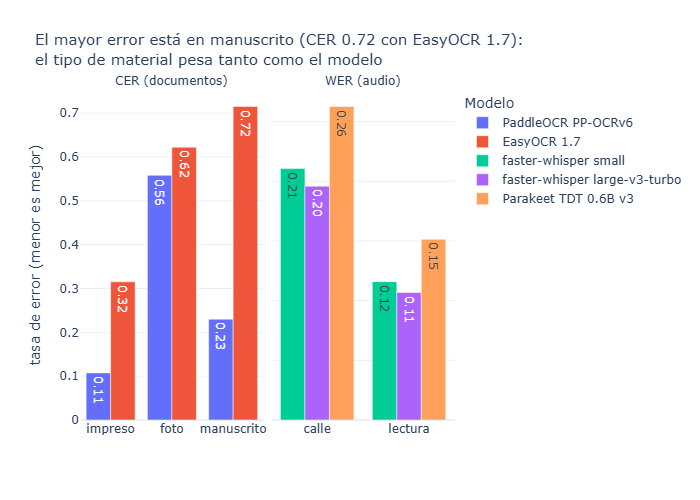

In [6]:
def mostrar(fig):
    "Gráfico interactivo y una imagen PNG para que se vea en GitHub."
    fig.update_layout(template="plotly_white", title_font_size=15, margin=dict(t=90))
    try:
        fig.show(renderer="plotly_mimetype+png")
    except (ValueError, RuntimeError) as e:   # sin kaleido no se puede exportar la imagen
        print(f"(sin imagen estática: {e})")
        fig.show()


por_grupo = pd.DataFrame([
    {"metrica": f"{metrica} ({nombre})", "grupo": grupo, "modelo": modelo,
     "error": error(metrica, referencias_de(muestra, g.id), list(g.texto))}
    for evaluacion, muestra, metrica, nombre in [(eval_docs, muestra_docs, "CER", "documentos"),
                                                 (eval_clips, muestra_clips, "WER", "audio")]
    for (grupo, modelo), g in evaluacion.groupby(["grupo", "modelo"], sort=False)
])
peor = por_grupo.loc[por_grupo.error.idxmax()]
fig = px.bar(por_grupo, x="grupo", y="error", color="modelo", barmode="group", facet_col="metrica",
             text_auto=".2f", labels={"grupo": "", "error": "tasa de error (menor es mejor)", "modelo": "Modelo"},
             title=f"El mayor error está en {peor.grupo} ({peor.metrica.split()[0]} {peor.error:.2f} con {peor.modelo}):"
                   "<br>el tipo de material pesa tanto como el modelo")
fig.update_xaxes(matches=None)
fig.update_yaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
mostrar(fig)

## 5. Extracción estructurada con LLM

**Modelo:** `qwen2.5:3b` (Alibaba, Apache 2.0) local con Ollama, en CPU y sin enviar los textos a ningún servicio externo. `temperature=0` y un **esquema JSON** obligatorio (salida estructurada de Ollama), así el modelo no puede agregar campos.

| Modalidad | Campos |
|---|---|
| documento | `modalidad`, `tema`, `resumen`, `emisor`, `fecha`, `monto` (los tres últimos `null` si no aparecen en el texto) |
| audio | `modalidad`, `tema`, `resumen`, `numero_hablantes` (marcas `[HABLANTE_n]` distintas), `citas_clave` (frases copiadas del texto) |

Se envían los primeros 3 500 caracteres de cada texto (OCR, o ASR ya seudonimizado). La extracción cubre los 38 archivos del corpus procesado (25 documentos y 13 clips).

In [7]:
MODELO_LLM = "qwen2.5:3b"
TEXTO, NULO = {"type": "string"}, {"type": ["string", "null"]}
ESQUEMAS = {
    "documento": {"type": "object", "required": ["modalidad", "tema", "resumen", "emisor", "fecha", "monto"],
                  "properties": {"modalidad": TEXTO, "tema": TEXTO, "resumen": TEXTO,
                                 "emisor": NULO, "fecha": NULO, "monto": NULO}},
    "audio": {"type": "object", "required": ["modalidad", "tema", "resumen", "numero_hablantes", "citas_clave"],
              "properties": {"modalidad": TEXTO, "tema": TEXTO, "resumen": TEXTO,
                             "numero_hablantes": {"type": ["integer", "null"]},
                             "citas_clave": {"type": "array", "items": TEXTO}}},
}
INSTRUCCIONES = {
    "documento": ("Eres un archivista. Lee el texto obtenido por OCR de un documento peruano (puede tener errores "
                  "de lectura) y devuelve SOLO un JSON con: modalidad (\"documento\"), tema (máximo 6 palabras), "
                  "resumen (1 o 2 oraciones en español), emisor (persona o institución que firma o publica), "
                  "fecha (tal como aparece) y monto (cantidad de dinero tal como aparece). Si emisor, fecha o monto "
                  "no aparecen literalmente en el texto, usa null. No inventes datos."),
    "audio": ("Eres un archivista. Lee la transcripción automática de un audio en español peruano (las marcas "
              "[HABLANTE_n] separan voces y [PERSONA_n] reemplaza nombres) y devuelve SOLO un JSON con: modalidad "
              "(\"audio\"), tema (máximo 6 palabras), resumen (1 o 2 oraciones en español), numero_hablantes "
              "(cuántas marcas [HABLANTE_n] distintas hay, o null si no hay marcas) y citas_clave (1 a 3 frases "
              "copiadas literalmente del texto). No inventes datos."),
}


def extraer(id_, modalidad, texto):
    "Campos JSON de un texto con Ollama (o la respuesta guardada)."
    if guardado := crudo("llm", id_):
        return guardado
    cuerpo = {"model": MODELO_LLM, "stream": False, "format": ESQUEMAS[modalidad],
              "options": {"temperature": 0, "num_ctx": 4096, "seed": 7},
              "messages": [{"role": "system", "content": INSTRUCCIONES[modalidad]},
                           {"role": "user", "content": texto[:3500]}]}
    pedido = urllib.request.Request("http://localhost:11434/api/chat", data=json.dumps(cuerpo).encode(),
                                    headers={"Content-Type": "application/json"})
    t0 = time.perf_counter()
    with urllib.request.urlopen(pedido, timeout=600) as r:
        campos = json.loads(json.loads(r.read())["message"]["content"])
    return guardar("llm", id_, {"id": id_, "modalidad": modalidad, "campos": campos, "modelo_llm": MODELO_LLM,
                                "segundos": round(time.perf_counter() - t0, 1), "fecha": time.strftime("%Y-%m-%d")})


textos = pd.concat([
    documentos[["id", "texto_ocr"]].rename(columns={"texto_ocr": "texto"}).assign(modalidad="documento"),
    transcripciones[["id", "texto_asr"]].rename(columns={"texto_asr": "texto"}).assign(modalidad="audio"),
])
salidas = [extraer(t.id, t.modalidad, t.texto) for t in textos.itertuples()]
extraccion = pd.DataFrame([{"id": s["id"], "modalidad": s["modalidad"],
                            "campos_json": json.dumps(s["campos"], ensure_ascii=False),
                            "modelo_llm": s["modelo_llm"], "fecha": s["fecha"]} for s in salidas])
extraccion.to_csv(DATOS / "extraccion_llm.csv", index=False, encoding="utf-8")
print(f"datos/extraccion_llm.csv: {extraccion.shape} · {sum(s['segundos'] for s in salidas) / 60:.0f} min de LLM en CPU")
extraccion.head()

datos/extraccion_llm.csv: (38, 5) · 20 min de LLM en CPU


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Manuscrito...",qwen2.5:3b,2026-10-25
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""literatura...",qwen2.5:3b,2026-10-25
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""historia p...",qwen2.5:3b,2026-10-25
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""fábula"", ""...",qwen2.5:3b,2026-10-25
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""literatura...",qwen2.5:3b,2026-10-25


### 5.1 Auditoría humana de 20 extracciones

Se eligen **al azar** (semilla fija) 10 documentos y 10 audios del corpus procesado. Una extracción es **completamente correcta** solo si cumple todos estos criterios, revisados leyendo el texto completo:

1. `tema` y `resumen` describen lo que dice el texto, sin agregar hechos que no están.
2. `emisor`, `fecha` y `monto` (documentos) son `null` cuando no aparecen, o coinciden con lo que dice el texto cuando aparecen.
3. `numero_hablantes` (audio) coincide con las marcas `[HABLANTE_n]` distintas, y cada `citas_clave` está copiada del texto.
4. No hay datos inventados en ningún campo.

La columna `chequeo_automatico` solo ayuda a revisar: dice si las fechas, montos, emisores y citas aparecen tal cual en el texto y si el número de hablantes coincide. La decisión `correcta` (`sí`/`no`) y el comentario los pone una persona en `datos/auditoria_llm.csv`.

In [8]:
def chequeo(fila, texto):
    "Ayuda para la auditoría: qué campos se pueden verificar contra el texto."
    campos, plano = json.loads(fila.campos_json), normalizar(texto)
    notas = []
    if fila.modalidad == "documento":
        for campo in ["emisor", "fecha", "monto"]:
            if campos.get(campo):
                notas.append(f"{campo} {'está' if normalizar(str(campos[campo])) in plano else 'NO está'} en el texto")
    else:
        marcas = len(set(re.findall(r"\[HABLANTE_\d+\]", texto)))
        notas.append("hablantes coincide" if campos.get("numero_hablantes") == marcas
                     else f"hablantes NO coincide ({marcas} marcas)")
        citas = campos.get("citas_clave") or []
        notas.append(f"{sum(normalizar(c) in plano for c in citas)}/{len(citas)} citas están en el texto")
    return "; ".join(notas) or "sin campos verificables"


ruta_auditoria = DATOS / "auditoria_llm.csv"
if ruta_auditoria.exists():          # no se pisa una auditoría ya hecha
    auditoria = pd.read_csv(ruta_auditoria, keep_default_na=False)
else:
    auditoria = pd.concat([extraccion[extraccion.modalidad == m].sample(10, random_state=2026)
                           for m in ["documento", "audio"]])
    texto_de = dict(zip(textos.id, textos.texto))
    auditoria["chequeo_automatico"] = [chequeo(f, texto_de[f.id]) for f in auditoria.itertuples()]
    auditoria["correcta"], auditoria["comentario"] = "", ""
    auditoria.to_csv(ruta_auditoria, index=False, encoding="utf-8")

revisadas = auditoria[auditoria.correcta.astype(str).str.strip() != ""]
correctas = revisadas.correcta.astype(str).str.lower().isin(["sí", "si", "true", "1"]).sum()
print(f"Auditoría: {len(revisadas)}/20 revisadas · {correctas}/{len(auditoria)} completamente correctas "
      f"({correctas / len(auditoria):.0%})")
auditoria[["id", "modalidad", "campos_json", "chequeo_automatico", "correcta", "comentario"]]

Auditoría: 0/20 revisadas · 0/20 completamente correctas (0%)


,id,modalidad,campos_json,chequeo_automatico,correcta,comentario
0,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""fábula"", ""...",sin campos verificables,,
1,doc_016,documento,"{""modalidad"": ""documento"", ""tema"": ""arrendamie...",fecha NO está en el texto,,
2,doc_019,documento,"{""modalidad"": ""documento"", ""tema"": ""viaje y co...",fecha está en el texto,,
3,doc_017,documento,"{""modalidad"": ""documento"", ""tema"": ""presidenci...",emisor está en el texto; fecha está en el texto,,
4,doc_015,documento,"{""modalidad"": ""documento"", ""tema"": ""riesgo leg...",fecha está en el texto; monto está en el texto,,
5,doc_025,documento,"{""modalidad"": ""documento"", ""tema"": ""enfermedad...",emisor está en el texto; fecha está en el texto,,
6,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""literatura...",sin campos verificables,,
7,doc_009,documento,"{""modalidad"": ""documento"", ""tema"": ""comunicaci...",emisor está en el texto; fecha está en el texto,,
8,doc_011,documento,"{""modalidad"": ""documento"", ""tema"": ""anulación ...",fecha está en el texto,,
9,doc_018,documento,"{""modalidad"": ""documento"", ""tema"": ""recibo"", ""...",fecha está en el texto,,


## 6. Casos difíciles

Los tres archivos con más error de cada modalidad, con el comienzo de la referencia y de la salida del modelo de la Parte 1, para ver **qué** falla.

In [9]:
for evaluacion, muestra, modelo in [(eval_docs, muestra_docs, "PaddleOCR PP-OCRv6"),
                                    (eval_clips, muestra_clips, "faster-whisper large-v3-turbo")]:
    for f in evaluacion[evaluacion.modelo == modelo].astype({"error": float}).nlargest(3, "error").itertuples():
        print(f"━━ {f.id} ({f.grupo}) · error {f.error:.2f} con {modelo}")
        print("   referencia:", normalizar(referencias_de(muestra, [f.id])[0])[:220])
        print("   modelo:    ", normalizar(f.texto)[:220], "\n")

━━ doc_009 (foto) · error 0.66 con PaddleOCR PP-OCRv6
   referencia: thēmis revista de derecho 88 julio diciembre 2025 pp 65 88 issn 1810 9934 comunicaciones comerciales submarinas que llegaban a un país sin especificaciones adicionales e incluso la ausencia de normas publicadas para la s
   modelo:     icación etros mate thêmis revista de derecho 88 jullo diclembre 2025 pp 65 88 issn 1810 9934 comunicaciones harov sentencia la selección un ámbito reservado la existencia misma de debe identificar los procesos de comunic 

━━ doc_010 (foto) · error 0.64 con PaddleOCR PP-OCRv6
   referencia: no todo es lo que parece el control constitucional vía amparo contra arbitrajes fraudulentos i introducción la popularidad del arbitraje en el perú ha ido incrementando progresivamente en el tiempo desde inicios de este 
   modelo:     he t 1 introducción la popularidad del arbitraje en el perú ha ido incre mentando progresivamente en el tiempo desde inicios de este siglo se ha vuelto una práctica ca

## 7. Exportación para el dashboard

- `datos/evaluacion_modelos.csv`: una fila por modelo con su error global (CER o WER), su latencia y si es el **seleccionado**.
- `datos/evaluacion_por_archivo.csv`: el error y el texto de cada modelo en cada archivo de la muestra.

In [10]:
SELECCIONADOS = {"PaddleOCR PP-OCRv6", "faster-whisper large-v3-turbo"}   # ver la decisión (sección 8)

evaluacion_modelos = pd.concat([
    tabla_docs.rename(columns={"segundos por página": "latencia"}).assign(unidad_latencia="segundos por página"),
    tabla_clips.rename(columns={"RTF": "latencia"}).assign(unidad_latencia="RTF"),
]).reindex(columns=["modalidad", "modelo", "rol", "metrica", "valor", "latencia", "unidad_latencia"])
evaluacion_modelos["seleccionado"] = evaluacion_modelos.modelo.isin(SELECCIONADOS)
evaluacion_modelos.to_csv(DATOS / "evaluacion_modelos.csv", index=False, encoding="utf-8")

por_archivo = pd.concat([eval_docs, eval_clips])[["id", "modalidad", "grupo", "modelo", "rol", "error", "segundos", "texto"]]
por_archivo.to_csv(DATOS / "evaluacion_por_archivo.csv", index=False, encoding="utf-8")
print("datos/evaluacion_modelos.csv:", evaluacion_modelos.shape)
print("datos/evaluacion_por_archivo.csv:", por_archivo.shape)
evaluacion_modelos

datos/evaluacion_modelos.csv: (5, 8)
datos/evaluacion_por_archivo.csv: (47, 8)


,modalidad,modelo,rol,metrica,valor,latencia,unidad_latencia,seleccionado
0,documento,PaddleOCR PP-OCRv6,línea base,CER,0.3734,106.64,segundos por página,True
1,documento,EasyOCR 1.7,alternativo,CER,0.5352,57.88,segundos por página,False
0,audio,faster-whisper small,línea base,WER,0.1591,0.46,RTF,False
1,audio,faster-whisper large-v3-turbo,Parte 1,WER,0.1474,0.70,RTF,True
2,audio,Parakeet TDT 0.6B v3,alternativo,WER,0.2020,0.22,RTF,False


## 8. Decisión y reflexión

### Documentos: se elige PaddleOCR

| Modelo | CER global | Impresos | Fotos | Manuscritos | Segundos por página (CPU) |
|---|---|---|---|---|---|
| PaddleOCR PP-OCRv6 (línea base) | **0,37** | **0,11** | **0,56** | **0,23** | 107 |
| EasyOCR 1.7 (alternativo) | 0,54 | 0,32 | 0,62 | 0,72 | 58 |

PaddleOCR gana en los tres tipos de documento. EasyOCR tarda la mitad, pero en un archivo cada documento se lee **una sola vez y por lotes**, así que la precisión pesa más que la latencia. Además, el costo de PaddleOCR se debe sobre todo a que en Windows hubo que desactivar oneDNN; con GPU baja a pocos segundos por página.

**Reflexión por tipo de documento:**

- **Impresos (mejor caso).** El CER es casi cero en `doc_001` y `doc_003` (0,007). El 0,32 de `doc_002` no se debe a palabras mal leídas: la página trae un poema **a dos columnas**, PaddleOCR une las líneas de ambas columnas de arriba hacia abajo y la referencia lee una columna y después la otra. El CER castiga ese orden aunque cada palabra esté bien.
- **Fotos (peor caso).** Al mismo problema de columnas (las revistas de THĒMIS van a dos columnas) se suman el texto de la página vecina que entra en la foto (`doc_009` empieza con «icación / etros mate.»), la sombra y la inclinación. `doc_011`, a una sola columna, baja a 0,18.
- **Manuscritos.** PaddleOCR (0,23) resiste mucho mejor la letra cursiva del siglo XIX que EasyOCR (0,72), entrenado sobre todo con texto impreso. Los errores caen justo en los datos que más le importan a un archivo: nombres y abreviaturas («don Preardo Palma» por «don Ricardo Palma»).

**Qué mejoraría el resultado sin cambiar de modelo:** analizar el diseño de la página antes del OCR (detectar columnas, por ejemplo con PP-StructureV3) y recortar los márgenes de las fotos.

### Audio: se mantiene faster-whisper large-v3-turbo

| Modelo | WER global (9 clips) | RTF (CPU) |
|---|---|---|
| faster-whisper `small` (línea base) | 0,159 | 0,46 |
| faster-whisper `large-v3-turbo` (Parte 1) | **0,147** | 0,70 |
| Parakeet TDT 0.6B v3 (alternativo) | 0,202 | **0,22** |

La muestra de audio quedó en **9 clips** (5 en la calle y 4 lecturas, sin clips rurales), uno menos que los 10 pedidos. Turbo tiene el menor WER global y gana en 3 de las 4 lecturas, pero `small` queda muy cerca (y gana en `clip_002`, `clip_006`, `clip_007` y `clip_008`) con un RTF menor. Parakeet es unas 3 veces más rápido que turbo, pero comete más errores en español peruano coloquial. Para un archivo, donde cada audio se transcribe una vez, se elige **turbo**. Si hubiera que transcribir en vivo o en gran volumen sin GPU, Parakeet sería la opción por latencia.

**Reflexión por tipo de audio:** las **lecturas** (una voz y buen micrófono) son el mejor caso (WER de 0,05 a 0,25). En la **calle**, el ruido y las voces lejanas disparan el error: en `clip_003` los tres modelos rondan 0,8 porque casi todo lo que dice el entrevistado se pierde bajo el ruido. Los clips **rurales en quechua** quedaron fuera del corpus porque ningún modelo de esta comparación reconoce quechua (MMS sería el siguiente paso).

### Extracción con LLM

Qwen2.5 3B extrajo los 38 archivos en unos 20 minutos de CPU, sin enviar los textos fuera de la computadora. La verificación automática de la auditoría ya muestra los errores típicos de un modelo pequeño:

- cuenta mal los hablantes (`clip_001`: dice 3 y hay 2 marcas);
- inventa un prefijo en las citas («Habla 2:», en `clip_004`);
- pone una fecha que no está en el texto (`doc_016`);
- en las cartas confunde al destinatario con el emisor y copia el error del OCR (`doc_017`: emisor «don Preardo Palma»).

Por eso la extracción sirve para buscar y filtrar, pero sus campos deben revisarse antes de usarlos como dato.